# SASRec для HSE RecSys Challenge 2026 — автономный Colab

Тетрадка работает в чистом Google Colab и не требует репозитория. Включите **Runtime → Change runtime type → T4 GPU**, загрузите четыре CSV и выполните **Run all**. По умолчанию выполняются validation training, full-data refit и экспорт. Исторический ориентир (не результат нового запуска): local Recall@10 = 0.141546, epoch 48; Kaggle ~0.28 сообщён командой.


## 1. Окружение

RePlay 0.22.0 официально поддерживает Python 3.10–3.14. Сохраняем предустановленный CUDA PyTorch Colab: не запрашиваем другую версию torch и проверяем, что после установки он не изменился.


In [1]:
import importlib.metadata as metadata
import platform
import subprocess
import sys

if not ((3, 10) <= sys.version_info[:2] < (3, 15)):
    raise RuntimeError(f"RePlay 0.22.0 требует Python >=3.10,<3.15; получен {platform.python_version()}")
try:
    torch_before = metadata.version("torch")
except metadata.PackageNotFoundError as error:
    raise RuntimeError("Выберите Colab GPU runtime с предустановленным PyTorch") from error

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "--quiet",
    "replay-rec==0.22.0", "lightning==2.5.6", "torchmetrics==1.8.2", "pyarrow==18.1.0",
])

import torch
torch_after = metadata.version("torch")
if torch_after != torch_before:
    raise RuntimeError(f"Установка изменила Colab PyTorch: {torch_before} -> {torch_after}; перезапустите runtime")
if not torch.cuda.is_available():
    raise RuntimeError("CUDA недоступна: включите T4 GPU и снова выполните Run all")
print({"python": platform.python_version(), "torch": torch.__version__,
       "cuda": torch.version.cuda, "gpu": torch.cuda.get_device_name(0),
       "replay-rec": metadata.version("replay-rec"),
       "lightning": metadata.version("lightning"),
       "torchmetrics": metadata.version("torchmetrics")})


{'python': '3.13.16', 'torch': '2.11.0+cu130', 'cuda': '13.0', 'gpu': 'Tesla T4', 'replay-rec': '0.22.0', 'lightning': '2.5.6', 'torchmetrics': '1.8.2'}


## 2. Входные файлы и режим

Единственные входы: `events.csv`, `user_features.csv`, `item_features.csv`, `submission_sample.csv`. Если файлов ещё нет в `/content`, откроется стандартный upload. Для inference из готового bundle установите `RELOAD_ONLY=True`; CSV всё равно нужны, потому что checkpoint не содержит пользовательские истории.


In [2]:
from pathlib import Path

RELOAD_ONLY = False
RELOAD_BUNDLE_NAME = "sasrec_full_bundle.zip"
REQUIRED_FILES = {"events.csv", "user_features.csv", "item_features.csv", "submission_sample.csv"}
CONTENT = Path("/content")
missing = sorted(name for name in REQUIRED_FILES if not (CONTENT / name).is_file())
if missing:
    from google.colab import files
    print("Загрузите:", missing)
    uploaded = files.upload()
    for name, payload in uploaded.items():
        (CONTENT / Path(name).name).write_bytes(payload)
missing = sorted(name for name in REQUIRED_FILES if not (CONTENT / name).is_file())
if missing:
    raise FileNotFoundError(f"Не найдены обязательные CSV: {missing}")
if RELOAD_ONLY and not (CONTENT / RELOAD_BUNDLE_NAME).is_file():
    from google.colab import files
    print("Загрузите", RELOAD_BUNDLE_NAME)
    uploaded = files.upload()
    for name, payload in uploaded.items():
        (CONTENT / Path(name).name).write_bytes(payload)
    if not (CONTENT / RELOAD_BUNDLE_NAME).is_file():
        raise FileNotFoundError(RELOAD_BUNDLE_NAME)
OUTPUT_DIR = CONTENT / "sasrec_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)


## 3. Встроенная эталонная логика

Следующие ячейки сгенерированы из `src/recsys`; импортов проекта во время исполнения нет.


In [3]:
"""Загрузка, EDA, хронологический split и отображения ID."""

from __future__ import annotations

from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import sparse

FILENAMES = ("events.csv", "user_features.csv", "item_features.csv", "submission_sample.csv")


@dataclass(frozen=True)
class IdMappings:
    user_ids: tuple[str, ...]
    item_ids: tuple[str, ...]

    @property
    def user_to_index(self) -> dict[str, int]:
        return {value: index for index, value in enumerate(self.user_ids)}

    @property
    def item_to_index(self) -> dict[str, int]:
        return {value: index for index, value in enumerate(self.item_ids)}

    def to_dict(self) -> dict[str, list[str]]:
        return {"user_ids": list(self.user_ids), "item_ids": list(self.item_ids)}

    @classmethod
    def from_dict(cls, value: dict[str, list[str]]) -> "IdMappings":
        return cls(tuple(value["user_ids"]), tuple(value["item_ids"]))


def resolve_data_dir(explicit: str | Path | None = None) -> Path:
    """Находит единственную папку, содержащую все четыре входных CSV."""
    candidates = [Path(explicit)] if explicit is not None else [Path("data"), Path("."), Path("/content/data")]
    matches = [path.resolve() for path in candidates if all((path / name).is_file() for name in FILENAMES)]
    if len(matches) != 1:
        raise FileNotFoundError(f"Ожидалась одна папка с {FILENAMES}; найдено: {matches}")
    return matches[0]


def load_data(data_dir: str | Path) -> dict[str, pd.DataFrame]:
    path = Path(data_dir)
    events = pd.read_csv(path / "events.csv", dtype={"user_id": str, "item_id": str})
    users = pd.read_csv(path / "user_features.csv", dtype={"user_id": str})
    items = pd.read_csv(path / "item_features.csv", dtype={"item_id": str})
    sample = pd.read_csv(path / "submission_sample.csv", dtype={"user_id": str, "item_id": str})
    if set(events) != {"user_id", "item_id", "rating", "timestamp"}:
        raise ValueError("events.csv имеет неожиданную схему")
    if list(sample) != ["user_id", "item_id"]:
        raise ValueError("submission_sample.csv должен содержать user_id, item_id")
    if events.isna().any().any() or not events["rating"].between(1, 5).all():
        raise ValueError("В событиях есть пропуски или rating вне [1, 5]")
    if events.duplicated(["user_id", "item_id"]).any():
        raise ValueError("Повторные пары user-item требуют отдельной политики")
    return {"events": events, "user_features": users, "item_features": items, "sample": sample}


def eda_summary(tables: dict[str, pd.DataFrame]) -> pd.DataFrame:
    return pd.DataFrame([
        {"table": name, "rows": len(frame), "columns": len(frame.columns),
         "missing": int(frame.isna().sum().sum()), "duplicates": int(frame.duplicated().sum())}
        for name, frame in tables.items()
    ])


def chronological_user_split(events: pd.DataFrame, validation_fraction: float = 0.20) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Скрывает ceil(20%) последних событий каждого пользователя."""
    if not 0 < validation_fraction < 1:
        raise ValueError("validation_fraction должен лежать между 0 и 1")
    ordered = events.sort_values(["user_id", "timestamp"], kind="stable").copy()
    sizes = ordered.groupby("user_id")["item_id"].transform("size")
    if (sizes < 2).any():
        raise ValueError("Для split нужно минимум два события у каждого пользователя")
    tail = np.ceil(sizes * validation_fraction).astype(int).clip(lower=1)
    tail = np.minimum(tail, sizes - 1)
    positions = ordered.groupby("user_id").cumcount()
    valid_mask = positions >= sizes - tail
    train, valid = ordered.loc[~valid_mask].copy(), ordered.loc[valid_mask].copy()
    if not (train.groupby("user_id")["timestamp"].max() < valid.groupby("user_id")["timestamp"].min()).all():
        raise AssertionError("Нарушена хронология: проверьте одинаковые timestamp")
    if not set(train.index).isdisjoint(valid.index):
        raise AssertionError("Train и validation пересекаются")
    return train, valid


def make_mappings(user_features: pd.DataFrame, item_features: pd.DataFrame) -> IdMappings:
    return IdMappings(tuple(sorted(user_features["user_id"].astype(str).unique())),
                      tuple(sorted(item_features["item_id"].astype(str).unique())))


def interaction_matrix(events: pd.DataFrame, mappings: IdMappings) -> sparse.csr_matrix:
    rows = events["user_id"].map(mappings.user_to_index)
    cols = events["item_id"].map(mappings.item_to_index)
    if rows.isna().any() or cols.isna().any():
        raise ValueError("Событие содержит ID вне mappings")
    matrix = sparse.csr_matrix((np.ones(len(events), dtype=np.float32), (rows.astype(int), cols.astype(int))),
                               shape=(len(mappings.user_ids), len(mappings.item_ids)), dtype=np.float32)
    matrix.sum_duplicates()
    matrix.data[:] = 1.0
    return matrix


def ground_truth(events: pd.DataFrame) -> dict[str, set[str]]:
    return events.groupby("user_id")["item_id"].agg(set).to_dict()


In [4]:
"""Метрики локальной валидации."""

from __future__ import annotations

from collections.abc import Mapping, Sequence
from typing import Hashable


def recall_at_k(
    recommendations: Mapping[Hashable, Sequence[Hashable]],
    ground_truth: Mapping[Hashable, Sequence[Hashable] | set[Hashable]],
    k: int = 10,
) -> float:
    """Macro Recall@k по пользователям с непустым target.

    Дубликаты рекомендаций считаются ошибкой, а не дополнительными попаданиями.
    """
    if k <= 0:
        raise ValueError("k должен быть положительным")

    recalls: list[float] = []
    for user, relevant_items in ground_truth.items():
        relevant = set(relevant_items)
        if not relevant:
            continue
        predicted = list(recommendations.get(user, ()))[:k]
        if len(predicted) != len(set(predicted)):
            raise ValueError(f"Повторные рекомендации для {user}")
        recalls.append(len(relevant.intersection(predicted)) / len(relevant))
    if not recalls:
        raise ValueError("Нет пользователей с непустым target")
    return float(sum(recalls) / len(recalls))


In [5]:
"""Seen filtering, top-10 и экспорт submission.csv."""

from __future__ import annotations

from pathlib import Path
from collections.abc import Mapping, Sequence

import numpy as np
import pandas as pd
from scipy import sparse


def top_k_unseen(scores: np.ndarray, item_ids: Sequence[str], seen_indices: Sequence[int], k: int = 10,
                 popularity: np.ndarray | None = None) -> list[str]:
    values = np.asarray(scores, dtype=float).copy()
    values[np.asarray(seen_indices, dtype=int)] = -np.inf
    allowed = np.flatnonzero(np.isfinite(values))
    if len(allowed) < k:
        raise ValueError("Недостаточно unseen items для top-k")
    secondary = np.zeros_like(values) if popularity is None else np.asarray(popularity)
    order = np.lexsort((allowed, -secondary[allowed], -values[allowed]))
    return [str(item_ids[index]) for index in allowed[order[:k]]]


def recommendations_from_scores(scores: np.ndarray, users: Sequence[str], item_ids: Sequence[str],
                                seen: sparse.csr_matrix, user_to_index: Mapping[str, int], k: int = 10,
                                popularity: np.ndarray | None = None) -> dict[str, list[str]]:
    result = {}
    for offset, user_id in enumerate(users):
        row = user_to_index[user_id]
        seen_indices = seen.indices[seen.indptr[row]:seen.indptr[row + 1]]
        result[user_id] = top_k_unseen(scores[offset], item_ids, seen_indices, k, popularity)
    return result


def build_submission(sample: pd.DataFrame, recommendations: Mapping[str, Sequence[str]], k: int = 10) -> pd.DataFrame:
    output = sample[["user_id"]].copy()
    output["item_id"] = output["user_id"].map(lambda user: " ".join(map(str, recommendations[user])))
    if output["item_id"].str.split().map(len).ne(k).any():
        raise ValueError(f"Каждому пользователю нужно ровно {k} рекомендаций")
    if output["item_id"].str.split().map(lambda values: len(set(values))).ne(k).any():
        raise ValueError("В рекомендациях есть дубликаты")
    return output


def write_submission(path: str | Path, frame: pd.DataFrame) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    frame.to_csv(path, index=False)


In [6]:
"""RePlay SASRec: окна, causal next-item labels и переносимый checkpoint."""

from __future__ import annotations

from dataclasses import asdict, dataclass
import importlib.metadata
import json
from pathlib import Path
import shutil
import tempfile
from typing import Any
import zipfile

import numpy as np
import pandas as pd



@dataclass(frozen=True)
class SASRecConfig:
    max_sequence_length: int = 100
    window_stride: int = 50
    embedding_dim: int = 64
    num_heads: int = 2
    num_blocks: int = 2
    dropout: float = 0.2
    batch_size: int = 128
    prediction_batch_size: int = 256
    learning_rate: float = 1e-3
    weight_decay: float = 1e-5
    gradient_clip: float = 1.0
    max_epochs: int = 50
    early_stopping_patience: int = 8
    seed: int = 42


def encoded_histories(events: pd.DataFrame, mappings: IdMappings) -> dict[str, list[int]]:
    item_to_index = mappings.item_to_index
    ordered = events.sort_values(["user_id", "timestamp"], kind="stable")
    histories: dict[str, list[int]] = {}
    for user_id, item_id in ordered[["user_id", "item_id"]].itertuples(index=False):
        if item_id not in item_to_index:
            raise ValueError(f"Неизвестный item_id: {item_id}")
        histories.setdefault(str(user_id), []).append(item_to_index[str(item_id)])
    return histories


def sliding_windows(sequence: list[int], max_sequence_length: int = 100, stride: int = 50) -> list[list[int]]:
    """Окна длины <= max_len+1: последний элемент нужен как next-item label."""
    if max_sequence_length < 1 or stride < 1:
        raise ValueError("Длины окна и шага должны быть положительными")
    window_size = max_sequence_length + 1
    if len(sequence) <= window_size:
        return [sequence.copy()] if len(sequence) >= 2 else []
    starts = list(range(0, len(sequence) - window_size + 1, stride))
    last_start = len(sequence) - window_size
    if starts[-1] != last_start:
        starts.append(last_start)
    return [sequence[start:start + window_size] for start in starts]


def autoregressive_examples(sequence: list[int], max_sequence_length: int = 100,
                            stride: int = 50, padding_value: int = -1) -> tuple[np.ndarray, np.ndarray]:
    """Правое выравнивание input/next-item labels; padding labels равны -1."""
    windows = sliding_windows(sequence, max_sequence_length, stride)
    inputs = np.full((len(windows), max_sequence_length), padding_value, dtype=np.int64)
    labels = np.full_like(inputs, -1)
    for row, window in enumerate(windows):
        source, target = window[:-1], window[1:]
        inputs[row, -len(source):] = source
        labels[row, -len(target):] = target
    return inputs, labels


def causal_attention_mask(length: int) -> np.ndarray:
    """True выше диагонали: будущие позиции недоступны."""
    return np.triu(np.ones((length, length), dtype=bool), k=1)


def replay_training_frame(histories: dict[str, list[int]], mappings: IdMappings,
                          config: SASRecConfig) -> pd.DataFrame:
    """Одна строка на перекрывающееся окно, как ожидает ParquetModule RePlay."""
    user_to_index = mappings.user_to_index
    rows = [
        {"user_id": user_to_index[user_id], "item_id": window}
        for user_id, sequence in histories.items()
        for window in sliding_windows(sequence, config.max_sequence_length, config.window_stride)
    ]
    if not rows:
        raise ValueError("Нет последовательностей длины хотя бы два")
    return pd.DataFrame(rows)


def replay_prediction_frame(histories: dict[str, list[int]], mappings: IdMappings) -> pd.DataFrame:
    return pd.DataFrame({
        "user_id": [mappings.user_to_index[user] for user in histories],
        "item_id": [sequence for sequence in histories.values()],
        "seen_ids": [sequence for sequence in histories.values()],
    })


def version_info() -> dict[str, str]:
    versions = {}
    for package in ("replay-rec", "torch", "lightning", "numpy", "pandas"):
        try:
            versions[package] = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            versions[package] = "not-installed"
    return versions


def save_checkpoint_bundle(bundle_path: str | Path, checkpoint_path: str | Path,
                           mappings: IdMappings, config: SASRecConfig,
                           metrics: dict[str, Any]) -> Path:
    """ZIP содержит веса, mappings, config, metrics и версии для inference без fit."""
    bundle_path, checkpoint_path = Path(bundle_path), Path(checkpoint_path)
    if not checkpoint_path.is_file():
        raise FileNotFoundError(checkpoint_path)
    bundle_path.parent.mkdir(parents=True, exist_ok=True)
    manifest = {"format_version": 1, "checkpoint": "model.ckpt", "mappings": mappings.to_dict(),
                "config": asdict(config), "metrics": metrics, "versions": version_info()}
    with zipfile.ZipFile(bundle_path, "w", zipfile.ZIP_DEFLATED) as archive:
        archive.write(checkpoint_path, "model.ckpt")
        archive.writestr("manifest.json", json.dumps(manifest, ensure_ascii=False, indent=2))
    return bundle_path


def load_checkpoint_bundle(bundle_path: str | Path, output_dir: str | Path | None = None
                           ) -> tuple[Path, IdMappings, SASRecConfig, dict[str, Any]]:
    """Распаковывает bundle и возвращает всё необходимое для reload-only inference."""
    target = Path(output_dir) if output_dir is not None else Path(tempfile.mkdtemp(prefix="sasrec_reload_"))
    target.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(bundle_path) as archive:
        if not {"model.ckpt", "manifest.json"} <= set(archive.namelist()):
            raise ValueError("Некорректный checkpoint bundle")
        archive.extract("model.ckpt", target)
        manifest = json.loads(archive.read("manifest.json"))
    mappings = IdMappings.from_dict(manifest["mappings"])
    config = SASRecConfig(**manifest["config"])
    return target / "model.ckpt", mappings, config, manifest


def replay_components(config: SASRecConfig, item_count: int) -> dict[str, Any]:
    """Создаёт pinned RePlay 0.22.0 модель; import отложен для CPU-бейзлайнов."""
    try:
        from replay.data import FeatureHint, FeatureType
        from replay.data.nn import TensorFeatureInfo, TensorSchema
        from replay.nn.lightning import LightningModule
        from replay.nn.lightning.optimizer import OptimizerFactory
        from replay.nn.sequential import SasRec
    except ImportError as error:
        raise RuntimeError("Установите replay-rec==0.22.0") from error
    schema = TensorSchema([TensorFeatureInfo(
        name="item_id", is_seq=True, padding_value=item_count, cardinality=item_count,
        embedding_dim=config.embedding_dim, feature_type=FeatureType.CATEGORICAL,
        feature_hint=FeatureHint.ITEM_ID,
    )])
    network = SasRec.from_params(schema=schema, embedding_dim=config.embedding_dim,
                                 max_sequence_length=config.max_sequence_length,
                                 num_heads=config.num_heads, num_blocks=config.num_blocks,
                                 dropout=config.dropout)
    module = LightningModule(network, optimizer_factory=OptimizerFactory(
        optimizer="adam", learning_rate=config.learning_rate))
    return {"schema": schema, "model": module}


def create_replay_network(config: SASRecConfig, item_count: int) -> Any:
    """Создаёт именно `replay.nn.sequential.SasRec` для собственного цикла."""
    try:
        from replay.data import FeatureHint, FeatureSource, FeatureType
        from replay.data.nn import TensorFeatureInfo, TensorFeatureSource, TensorSchema
        from replay.nn.sequential import SasRec
    except ImportError as error:
        raise RuntimeError("Установите replay-rec==0.22.0") from error
    schema = TensorSchema([TensorFeatureInfo(
        name="item_id", feature_type=FeatureType.CATEGORICAL, is_seq=True,
        feature_hint=FeatureHint.ITEM_ID, cardinality=item_count, padding_value=item_count,
        embedding_dim=config.embedding_dim,
        feature_sources=[TensorFeatureSource(FeatureSource.INTERACTIONS, "item_id")],
    )])
    return SasRec.from_params(
        schema=schema, embedding_dim=config.embedding_dim, num_heads=config.num_heads,
        num_blocks=config.num_blocks, max_sequence_length=config.max_sequence_length,
        dropout=config.dropout,
    )


def fit_sasrec(histories: dict[str, list[int]], item_count: int, config: SASRecConfig,
               checkpoint_path: str | Path, validation_fn: Any | None = None,
               epochs: int | None = None, device: str = "cuda") -> tuple[Any, pd.DataFrame, int]:
    """Обучает autoregressive next-item objective и сохраняет лучшую validation-эпоху."""
    try:
        import torch
        from torch.utils.data import DataLoader, Dataset
    except ImportError as error:
        raise RuntimeError("Для SASRec нужен PyTorch") from error
    if device == "cuda" and not torch.cuda.is_available():
        raise RuntimeError("Включите GPU в Colab или явно передайте device='cpu' для smoke test")
    torch.manual_seed(config.seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(config.seed)
    padding = item_count

    class WindowDataset(Dataset):
        def __init__(self) -> None:
            self.windows = [window for sequence in histories.values() for window in
                            sliding_windows(sequence, config.max_sequence_length, config.window_stride)]

        def __len__(self) -> int:
            return len(self.windows)

        def __getitem__(self, index: int) -> tuple[Any, Any, Any]:
            window = self.windows[index]
            tokens = np.full(config.max_sequence_length + 1, padding, dtype=np.int64)
            tokens[-len(window):] = window
            inputs, labels = tokens[:-1], tokens[1:]
            mask = (inputs != padding) & (labels != padding)
            return torch.from_numpy(inputs), torch.from_numpy(labels), torch.from_numpy(mask)

    dataset = WindowDataset()
    if not len(dataset):
        raise ValueError("Нет последовательностей длины хотя бы два")
    loader = DataLoader(dataset, batch_size=config.batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(config.seed))
    model = create_replay_network(config, item_count).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=config.learning_rate, weight_decay=config.weight_decay)
    checkpoint_path = Path(checkpoint_path)
    checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
    history, best_score, best_epoch, stale = [], -np.inf, 0, 0
    for epoch in range(1, (epochs or config.max_epochs) + 1):
        model.train()
        total_loss, total_targets = 0.0, 0
        for tokens, labels, mask in loader:
            tokens, labels, mask = tokens.to(device), labels.to(device), mask.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = model(feature_tensors={"item_id": tokens}, padding_mask=tokens.ne(padding),
                         positive_labels=labels.unsqueeze(-1),
                         target_padding_mask=mask.unsqueeze(-1))["loss"]
            if not torch.isfinite(loss):
                raise FloatingPointError("SASRec loss не является конечным")
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), config.gradient_clip)
            optimizer.step()
            count = int(mask.sum())
            total_loss += float(loss.detach()) * count
            total_targets += count
        score = None if validation_fn is None else float(validation_fn(model))
        history.append({"epoch": epoch, "train_loss": total_loss / total_targets,
                        "local_recall_at_10": score})
        improved = validation_fn is None or score > best_score
        if improved:
            best_score = best_score if score is None else score
            best_epoch, stale = epoch, 0
            torch.save({"model_state": {k: v.detach().cpu() for k, v in model.state_dict().items()},
                        "config": asdict(config), "item_count": item_count, "epoch": epoch}, checkpoint_path)
        else:
            stale += 1
        if validation_fn is not None and stale >= config.early_stopping_patience:
            break
    restored = restore_replay_model(checkpoint_path, config, item_count, device=device)
    return restored, pd.DataFrame(history), best_epoch


def predict_scores(model: Any, histories: dict[str, list[int]], users: list[str], item_count: int,
                   config: SASRecConfig, device: str = "cuda",
                   trained_item_mask: np.ndarray | None = None) -> np.ndarray:
    """Возвращает full-catalog score; seen filtering выполняется общим submission-модулем."""
    import torch
    model.eval()
    batches = []
    for start in range(0, len(users), config.prediction_batch_size):
        batch_users = users[start:start + config.prediction_batch_size]
        inputs = np.full((len(batch_users), config.max_sequence_length), item_count, dtype=np.int64)
        for row, user_id in enumerate(batch_users):
            tail = histories.get(user_id, [])[-config.max_sequence_length:]
            if tail:
                inputs[row, -len(tail):] = tail
        tokens = torch.as_tensor(inputs, device=device)
        with torch.inference_mode():
            scores = model(feature_tensors={"item_id": tokens}, padding_mask=tokens.ne(item_count))["logits"]
        values = scores.float().cpu().numpy()
        if trained_item_mask is not None:
            values[:, ~np.asarray(trained_item_mask, dtype=bool)] = -np.inf
        batches.append(values)
    return np.concatenate(batches) if batches else np.empty((0, item_count), dtype=np.float32)


def trained_items(histories: dict[str, list[int]], item_count: int) -> np.ndarray:
    """Маска items с обучающим сигналом; cold embeddings нельзя рекомендовать."""
    mask = np.zeros(item_count, dtype=bool)
    for sequence in histories.values():
        mask[np.asarray(sequence, dtype=int)] = True
    return mask


def restore_replay_model(checkpoint_path: str | Path, config: SASRecConfig, item_count: int,
                         device: str = "cpu") -> Any:
    """Восстанавливает RePlay SasRec без обучения."""
    try:
        import torch
    except ImportError as error:
        raise RuntimeError("Для SASRec нужен PyTorch") from error
    payload = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    restored = create_replay_network(config, item_count)
    restored.load_state_dict(payload["model_state"])
    restored.to(device)
    restored.eval()
    return restored


def copy_best_checkpoint(source: str | Path, destination: str | Path) -> Path:
    """Явная операция для сохранения checkpoint лучшей validation-эпохи."""
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source, destination)
    return destination


## 4. Данные, 80/20 split и микротесты


In [7]:
import random
from IPython.display import display

SEED, K = 42, 10
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
CONFIG = SASRecConfig(max_sequence_length=100, window_stride=50, embedding_dim=64,
                      num_heads=2, num_blocks=2, max_epochs=50, seed=SEED)
tables = load_data(CONTENT)
events, user_features, item_features, sample = (
    tables[name] for name in ["events", "user_features", "item_features", "sample"])
mappings = make_mappings(user_features, item_features)
train, valid = chronological_user_split(events, 0.20)
targets = ground_truth(valid)
assert len(targets) > 0
assert set(train.index).isdisjoint(valid.index)
assert (train.groupby("user_id").timestamp.max() < valid.groupby("user_id").timestamp.min()).all()

# Независимые микротесты перед GPU-обучением.
tiny = pd.DataFrame({"user_id": ["u"] * 5, "item_id": list("abcde"),
                     "rating": [5] * 5, "timestamp": range(5)})
tiny_train, tiny_valid = chronological_user_split(tiny, .20)
assert tiny_valid.item_id.tolist() == ["e"]
inputs, labels = autoregressive_examples([3, 4, 5], max_sequence_length=5, stride=2)
assert inputs.shape == labels.shape == (1, 5)
assert inputs[0, -2:].tolist() == [3, 4] and labels[0, -2:].tolist() == [4, 5]
mask = causal_attention_mask(4)
assert mask[0, 3] and not mask[3, 0]
assert recall_at_k({"u": ["a", "x"]}, {"u": {"a", "b"}}, 2) == .5
roundtrip = IdMappings.from_dict(mappings.to_dict())
assert roundtrip == mappings
print({"events": len(events), "train": len(train), "validation": len(valid),
       "users": len(mappings.user_ids), "items": len(mappings.item_ids)})


{'events': 894149, 'train': 712916, 'validation': 181233, 'users': 6040, 'items': 3706}


## 5. Validation training и выбор эпохи

Holdout не попадает в histories для fit. Каждая эпоха оценивается по full-catalog Recall@10; checkpoint сохраняется только при улучшении. Seen filtering использует всю train-историю.


,epoch,train_loss,local_recall_at_10
0,1,7.546026,0.039933
1,2,6.845464,0.079475
2,3,6.335554,0.096036
3,4,6.105643,0.106364
4,5,5.971750,0.111010
5,6,5.886504,0.117033
6,7,5.826524,0.119591
7,8,5.781418,0.120714
8,9,5.747915,0.123128
9,10,5.720410,0.124965


{'best_epoch': 49, 'local_recall_at_10': 0.14121944693934138}


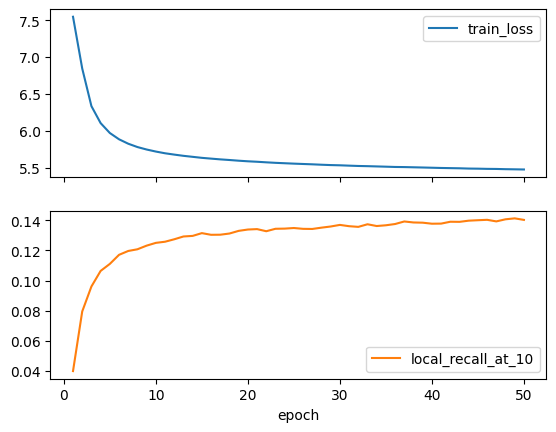

In [8]:
if not RELOAD_ONLY:
    train_histories = encoded_histories(train, mappings)
    train_seen = interaction_matrix(train, mappings)
    train_popularity = np.asarray(train_seen.sum(axis=0)).ravel()
    validation_users = list(targets)
    trained_mask = trained_items(train_histories, len(mappings.item_ids))

    def validation_recall(model):
        scores = predict_scores(model, train_histories, validation_users, len(mappings.item_ids),
                                CONFIG, device="cuda", trained_item_mask=trained_mask)
        recommendations = recommendations_from_scores(
            scores, validation_users, mappings.item_ids, train_seen,
            mappings.user_to_index, K, train_popularity)
        return recall_at_k(recommendations, targets, K)

    validation_checkpoint = OUTPUT_DIR / "sasrec_validation_best.ckpt"
    validation_model, validation_curve, best_epoch = fit_sasrec(
        train_histories, len(mappings.item_ids), CONFIG, validation_checkpoint,
        validation_fn=validation_recall, device="cuda")
    validation_curve.to_csv(OUTPUT_DIR / "validation_learning_curve.csv", index=False)
    best_recall = float(validation_curve.loc[
        validation_curve.epoch.eq(best_epoch), "local_recall_at_10"].iloc[0])
    validation_bundle = save_checkpoint_bundle(
        OUTPUT_DIR / "sasrec_validation_bundle.zip", validation_checkpoint, mappings, CONFIG,
        {"best_epoch": best_epoch, "validation_recall_at_10": best_recall,
         "learning_curve": validation_curve.to_dict(orient="records")})
    display(validation_curve)
    validation_curve.plot(x="epoch", y=["train_loss", "local_recall_at_10"], subplots=True)
    print({"best_epoch": best_epoch, "local_recall_at_10": best_recall})
    del validation_model
    torch.cuda.empty_cache()
else:
    print("RELOAD_ONLY: validation fit пропущен")


## 6. Full-data refit и submission

Создаётся новая модель и обучается на всех events ровно `best_epoch` эпох. Validation checkpoint не используется как submission-модель.


In [9]:
if not RELOAD_ONLY:
    full_histories = encoded_histories(events, mappings)
    full_seen = interaction_matrix(events, mappings)
    full_popularity = np.asarray(full_seen.sum(axis=0)).ravel()
    full_checkpoint = OUTPUT_DIR / "sasrec_full.ckpt"
    full_model, full_curve, _ = fit_sasrec(
        full_histories, len(mappings.item_ids), CONFIG, full_checkpoint,
        validation_fn=None, epochs=best_epoch, device="cuda")
    full_curve.to_csv(OUTPUT_DIR / "full_learning_curve.csv", index=False)
    submission_users = sample.user_id.tolist()
    full_mask = trained_items(full_histories, len(mappings.item_ids))
    full_scores = predict_scores(full_model, full_histories, submission_users,
                                 len(mappings.item_ids), CONFIG, device="cuda",
                                 trained_item_mask=full_mask)
    recommendations = recommendations_from_scores(
        full_scores, submission_users, mappings.item_ids, full_seen,
        mappings.user_to_index, K, full_popularity)

    # Обязательные инварианты submission.
    seen_by_user = events.groupby("user_id").item_id.agg(set).to_dict()
    assert len(recommendations) == len(submission_users) > 0
    for user_id in submission_users:
        values = recommendations[user_id]
        assert len(values) == len(set(values)) == K
        assert not (set(values) & seen_by_user.get(user_id, set()))
        assert set(values) <= set(mappings.item_ids)
    submission = build_submission(sample, recommendations, K)
    assert submission.user_id.tolist() == sample.user_id.tolist()
    write_submission(OUTPUT_DIR / "submission_sasrec.csv", submission)

    full_bundle = save_checkpoint_bundle(
        OUTPUT_DIR / "sasrec_full_bundle.zip", full_checkpoint, mappings, CONFIG,
        {"validation_recall_at_10": best_recall, "selected_epochs": best_epoch,
         "validation_curve": validation_curve.to_dict(orient="records"),
         "full_curve": full_curve.to_dict(orient="records")})

    # Serialize/reload: одинаковый input обязан дать тот же top-10.
    reloaded_path, reloaded_mappings, reloaded_config, _ = load_checkpoint_bundle(
        full_bundle, OUTPUT_DIR / "roundtrip")
    reloaded_model = restore_replay_model(reloaded_path, reloaded_config,
                                          len(reloaded_mappings.item_ids), device="cuda")
    reloaded_scores = predict_scores(
        reloaded_model, full_histories, submission_users, len(mappings.item_ids),
        reloaded_config, device="cuda", trained_item_mask=full_mask)
    reloaded_recommendations = recommendations_from_scores(
        reloaded_scores, submission_users, mappings.item_ids, full_seen,
        mappings.user_to_index, K, full_popularity)
    assert reloaded_recommendations == recommendations
    display(submission.head())
else:
    print("RELOAD_ONLY: full-data fit пропущен")


,user_id,item_id
0,0,213 3002 1461 3271 3185 700 2354 2275 1527 2082
1,1,1686 232 3311 1868 2338 3656 3205 3101 452 2336
2,2,1687 2354 702 488 570 3035 452 1754 1801 382
3,3,1223 1543 2564 1560 3409 1316 3013 3272 79 2862
4,4,1086 802 1545 2653 1337 3035 2814 570 488 2185


## 7. Reload-only inference

При `RELOAD_ONLY=True` модель, config и mappings читаются из bundle; fit не вызывается. Полная известная история из `events.csv` обязательна для sequence input и seen filtering.


In [10]:
if RELOAD_ONLY:
    bundle_path = CONTENT / RELOAD_BUNDLE_NAME
    checkpoint_path, mappings, CONFIG, manifest = load_checkpoint_bundle(
        bundle_path, OUTPUT_DIR / "reload_only")
    model = restore_replay_model(checkpoint_path, CONFIG, len(mappings.item_ids), device="cuda")
    histories = encoded_histories(events, mappings)
    seen = interaction_matrix(events, mappings)
    popularity = np.asarray(seen.sum(axis=0)).ravel()
    users_for_submission = sample.user_id.tolist()
    item_mask = trained_items(histories, len(mappings.item_ids))
    scores = predict_scores(model, histories, users_for_submission, len(mappings.item_ids),
                            CONFIG, device="cuda", trained_item_mask=item_mask)
    recommendations = recommendations_from_scores(
        scores, users_for_submission, mappings.item_ids, seen,
        mappings.user_to_index, K, popularity)
    submission = build_submission(sample, recommendations, K)
    seen_by_user = events.groupby("user_id").item_id.agg(set).to_dict()
    assert submission.user_id.tolist() == sample.user_id.tolist()
    assert all(len(set(recommendations[user])) == K for user in users_for_submission)
    assert all(not (set(recommendations[user]) & seen_by_user.get(user, set()))
               for user in users_for_submission)
    write_submission(OUTPUT_DIR / "submission_sasrec.csv", submission)
    print("Reload-only inference завершён", manifest["metrics"])


## 8. Архив результатов и скачивание


In [11]:
import shutil
from google.colab import files

archive = Path(shutil.make_archive(str(CONTENT / "sasrec_outputs"), "zip",
                                   root_dir=OUTPUT_DIR))
assert (OUTPUT_DIR / "submission_sasrec.csv").is_file()
print("Готово:", archive, OUTPUT_DIR / "submission_sasrec.csv")
files.download(str(OUTPUT_DIR / "submission_sasrec.csv"))
files.download(str(archive))


Готово: /content/sasrec_outputs.zip /content/sasrec_outputs/submission_sasrec.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>